## Makemore Part 2

In this notebook, we intend to build a character-level implementation of Bengio's paper: https://jmlr.org/papers/volume3/tmp/bengio03a.pdf$0 to get around the curse of dimensionality. We do this by tuning a character embedding for each character such that characters with similar semantic meaning are "nearby" in n-dimensional space, and then using this embeddings to predict the next word.

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('/content/drive/MyDrive/Colab Notebooks/Karpathy Zero to Hero/names', 'r').read().splitlines()
words[:8], len(words)

(['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia'],
 32033)

In [3]:
#building the vocabulary of the model

chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s,i in stoi.items()}

In [4]:
# building the block size - this is the size of the block that we will use to predict
# which letter should follow

block_size = 3

X = []
Y = []

for w in words[:5]:
  context = [0] * block_size
  print(w)

  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)

    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix]

X = torch.tensor(X) # training data
Y = torch.tensor(Y) # target

emma
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
... ---> a
..a ---> v
.av ---> a
ava ---> .
isabella
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
sophia
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [5]:
# Writing the Neural Network

C = torch.randn((27,2))
C

# C = list of embeddings for every character
# C[i] = embeddings of ith character

tensor([[-0.7686,  0.2833],
        [-0.5256, -0.5896],
        [-0.2158,  0.1689],
        [ 0.6457,  0.7224],
        [-0.2576, -1.7787],
        [ 0.3878,  0.4833],
        [-1.0311, -1.1502],
        [-0.2508,  1.2335],
        [-0.3173, -0.2237],
        [ 1.9819,  0.5443],
        [ 1.2440, -0.1138],
        [-0.1450, -0.3540],
        [-2.4044, -1.3797],
        [-0.3602,  0.0264],
        [ 0.0347, -1.6132],
        [ 0.2742, -0.5048],
        [-0.0536, -0.6478],
        [-1.1422,  1.3410],
        [ 1.8583, -0.3050],
        [ 0.4280,  1.8537],
        [ 0.1320,  1.7698],
        [ 0.1490,  0.7489],
        [ 1.2584,  0.3958],
        [ 0.3301,  0.2219],
        [ 0.5785,  0.6226],
        [-0.2183,  0.7972],
        [-0.1394, -1.2029]])

In [6]:
# getting the embedding of the 5th character

C[5]

# we can also use one-hot encoding to fetch this

F.one_hot(torch.tensor(5), num_classes = 27).float() # creating one hot encoding where 1 is at 5th spot


C[5], (F.one_hot(torch.tensor(5), num_classes = 27).float() @ C)

(tensor([0.3878, 0.4833]), tensor([0.3878, 0.4833]))

In [7]:
C, X, C[X] # C[X] = replaces every index in X with its embedding in C

(tensor([[-0.7686,  0.2833],
         [-0.5256, -0.5896],
         [-0.2158,  0.1689],
         [ 0.6457,  0.7224],
         [-0.2576, -1.7787],
         [ 0.3878,  0.4833],
         [-1.0311, -1.1502],
         [-0.2508,  1.2335],
         [-0.3173, -0.2237],
         [ 1.9819,  0.5443],
         [ 1.2440, -0.1138],
         [-0.1450, -0.3540],
         [-2.4044, -1.3797],
         [-0.3602,  0.0264],
         [ 0.0347, -1.6132],
         [ 0.2742, -0.5048],
         [-0.0536, -0.6478],
         [-1.1422,  1.3410],
         [ 1.8583, -0.3050],
         [ 0.4280,  1.8537],
         [ 0.1320,  1.7698],
         [ 0.1490,  0.7489],
         [ 1.2584,  0.3958],
         [ 0.3301,  0.2219],
         [ 0.5785,  0.6226],
         [-0.2183,  0.7972],
         [-0.1394, -1.2029]]),
 tensor([[ 0,  0,  0],
         [ 0,  0,  5],
         [ 0,  5, 13],
         [ 5, 13, 13],
         [13, 13,  1],
         [ 0,  0,  0],
         [ 0,  0, 15],
         [ 0, 15, 12],
         [15, 12,  9],
        

For clarity:

X is the training data. We are given X and asked to predict the next character. A row of X could be '...', or '..e', or 'emm'.

C is the lookup table of embeddings of each character. Characters are embedded in 2D space.

C[X] returns the training data, now represented as embeddings instead of as characters.

In [8]:
embed = C[X]

W1 = torch.randn((6,100)) # takes in 6 outputs: 3 characters with 2D embeddings
# outputs 100 values

b1 = torch.randn(100)

At this point, we would like to do something like this:

take the data (the 32 training examples + answers), pass them into the neurons, and get outputs. e.g:

emb @ W1 + b1

however, shapes don't match because emb is 32,3,2. Instead, we need emb to be 32,6.

In [9]:
torch.cat([embed[:, 0, :], embed[:, 1, :], embed[:, 2, :]], 1)
# here, we concatenate the embeddings to get a 32*6 array
# first row = first training example
# first two vals = embedding for first letter


tensor([[-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.3878,  0.4833],
        [-0.7686,  0.2833,  0.3878,  0.4833, -0.3602,  0.0264],
        [ 0.3878,  0.4833, -0.3602,  0.0264, -0.3602,  0.0264],
        [-0.3602,  0.0264, -0.3602,  0.0264, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.2742, -0.5048],
        [-0.7686,  0.2833,  0.2742, -0.5048, -2.4044, -1.3797],
        [ 0.2742, -0.5048, -2.4044, -1.3797,  1.9819,  0.5443],
        [-2.4044, -1.3797,  1.9819,  0.5443,  1.2584,  0.3958],
        [ 1.9819,  0.5443,  1.2584,  0.3958,  1.9819,  0.5443],
        [ 1.2584,  0.3958,  1.9819,  0.5443, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.5256, -0.5896,  1.2584,  0.3958],
        [-0.5256, -0.5896,  1.2584,  0.3

The above is similar to C[X], but instead of storing a training row as a list of lists, a training row is now 1 list and we concatenate the embeddings together in 1 list.

Now, the first 2 values in a list correspond to the embeddings of the first char, the second two correspond to the embeddings of the second char, etc.

In [10]:
# method doesn't generalize for multiple block sizes though
# we can use a different function instead

torch.cat(torch.unbind(embed, 1), 1)

# same as above, works for any block size

tensor([[-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.3878,  0.4833],
        [-0.7686,  0.2833,  0.3878,  0.4833, -0.3602,  0.0264],
        [ 0.3878,  0.4833, -0.3602,  0.0264, -0.3602,  0.0264],
        [-0.3602,  0.0264, -0.3602,  0.0264, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.2742, -0.5048],
        [-0.7686,  0.2833,  0.2742, -0.5048, -2.4044, -1.3797],
        [ 0.2742, -0.5048, -2.4044, -1.3797,  1.9819,  0.5443],
        [-2.4044, -1.3797,  1.9819,  0.5443,  1.2584,  0.3958],
        [ 1.9819,  0.5443,  1.2584,  0.3958,  1.9819,  0.5443],
        [ 1.2584,  0.3958,  1.9819,  0.5443, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.5256, -0.5896,  1.2584,  0.3958],
        [-0.5256, -0.5896,  1.2584,  0.3

There is actually still another, better, faster way to shape embedding - which relies on changing the metadata of how tensors are stored to reshape the Python representation without modifying the underlying memory.

In [11]:
embed.view(32, 6) # happens to be the same as the unbind + cat method

tensor([[-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.3878,  0.4833],
        [-0.7686,  0.2833,  0.3878,  0.4833, -0.3602,  0.0264],
        [ 0.3878,  0.4833, -0.3602,  0.0264, -0.3602,  0.0264],
        [-0.3602,  0.0264, -0.3602,  0.0264, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833,  0.2742, -0.5048],
        [-0.7686,  0.2833,  0.2742, -0.5048, -2.4044, -1.3797],
        [ 0.2742, -0.5048, -2.4044, -1.3797,  1.9819,  0.5443],
        [-2.4044, -1.3797,  1.9819,  0.5443,  1.2584,  0.3958],
        [ 1.9819,  0.5443,  1.2584,  0.3958,  1.9819,  0.5443],
        [ 1.2584,  0.3958,  1.9819,  0.5443, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.7686,  0.2833],
        [-0.7686,  0.2833, -0.7686,  0.2833, -0.5256, -0.5896],
        [-0.7686,  0.2833, -0.5256, -0.5896,  1.2584,  0.3958],
        [-0.5256, -0.5896,  1.2584,  0.3

In [12]:
h = embed.view(-1, 6) @ W1 + b1 # -1 allows pyTorch to infer what the dimension should be, generalizes to different sizes
h

tensor([[-0.8825,  2.2883, -1.7703,  ...,  0.1697,  0.2056,  0.2915],
        [-0.4225,  2.0671, -2.9621,  ..., -0.9679,  1.4139,  0.3361],
        [ 0.4083,  1.2887,  0.3319,  ...,  1.2586,  0.0105,  0.3055],
        ...,
        [-4.1249,  2.5385,  0.1918,  ...,  1.8304, -1.0107, -0.3147],
        [-1.4502,  2.8093, -3.6113,  ..., -1.9755,  1.5719, -0.3518],
        [ 0.6902,  0.8696,  3.9904,  ...,  3.5714, -1.6651, -0.3381]])

In [13]:
h = torch.tanh(h) # now between 0 and 1
h, h.shape

(tensor([[-0.7077,  0.9796, -0.9436,  ...,  0.1681,  0.2027,  0.2835],
         [-0.3991,  0.9685, -0.9947,  ..., -0.7478,  0.8883,  0.3240],
         [ 0.3870,  0.8588,  0.3203,  ...,  0.8507,  0.0105,  0.2964],
         ...,
         [-0.9995,  0.9876,  0.1895,  ...,  0.9499, -0.7661, -0.3047],
         [-0.8957,  0.9928, -0.9985,  ..., -0.9623,  0.9173, -0.3380],
         [ 0.5981,  0.7012,  0.9993,  ...,  0.9984, -0.9309, -0.3258]]),
 torch.Size([32, 100]))

In [14]:
# second layer

W2 = torch.randn((100, 27))

b2 = torch.randn(27)

In [15]:
logits = h @ W2 + b2
logits.shape

torch.Size([32, 27])

In [16]:
# normalize logits to probabilities

counts = logits.exp()
prob = counts / counts.sum(1, keepdim=True)

prob.shape

torch.Size([32, 27])

In [17]:
prob

tensor([[2.5893e-03, 9.7296e-01, 8.4889e-04, 4.4531e-04, 8.3111e-07, 4.4991e-05,
         5.0708e-08, 1.5509e-06, 1.7387e-07, 1.5960e-06, 8.4214e-04, 8.7689e-05,
         1.8003e-02, 1.9249e-07, 5.7287e-11, 1.0151e-05, 3.6736e-05, 4.0616e-04,
         1.7734e-06, 4.1448e-08, 1.7645e-11, 5.6379e-11, 1.0983e-12, 5.0090e-11,
         8.0752e-08, 3.7152e-03, 3.7576e-08],
        [2.5505e-05, 1.1575e-04, 5.1859e-06, 3.5071e-06, 1.4697e-08, 1.0227e-07,
         4.1885e-07, 1.1922e-05, 2.0333e-14, 5.5346e-07, 2.6696e-02, 2.4323e-04,
         5.5261e-01, 3.9739e-05, 2.4246e-11, 1.9681e-07, 1.8294e-09, 1.4087e-08,
         2.5753e-04, 1.0494e-10, 3.5759e-10, 8.7345e-13, 2.9435e-12, 1.9523e-11,
         3.2046e-07, 4.1999e-01, 4.2438e-10],
        [2.0388e-04, 3.5923e-03, 1.3325e-04, 2.3348e-07, 1.0058e-09, 2.2098e-05,
         2.3222e-06, 4.7313e-07, 1.1091e-12, 4.2299e-08, 2.1456e-02, 6.0584e-05,
         7.4307e-01, 9.2738e-04, 7.2979e-11, 7.5451e-05, 2.1244e-07, 3.0181e-06,
         9.8335e-

In [18]:
# again, for the loss we want to pluck the probability assigned to the correct character for each example

prob[torch.arange(32), Y]

tensor([4.4991e-05, 3.9739e-05, 9.2738e-04, 2.0103e-02, 2.1712e-06, 1.0151e-05,
        1.0676e-01, 1.2419e-13, 4.5038e-14, 2.6341e-16, 3.4699e-09, 3.3707e-10,
        9.7296e-01, 3.7112e-13, 1.6015e-06, 1.9405e-06, 1.5960e-06, 9.2525e-14,
        5.3109e-09, 8.0069e-06, 4.3696e-05, 1.1012e-01, 5.5503e-09, 1.5115e-03,
        8.7242e-06, 4.1448e-08, 8.1650e-11, 5.4155e-07, 6.1368e-05, 4.8096e-12,
        1.2478e-06, 2.3280e-08])

In [19]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(15.4905)

In [20]:
# Full model

block_size = 3

X = []
Y = []

for w in words:
  context = [0] * block_size

  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)

    context = context[1:] + [ix]

X = torch.tensor(X) # training data
Y = torch.tensor(Y) # target

X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [21]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True


In [22]:
for _ in range(10):
  # forward pass

  emb = C[X]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  #counts = logits.exp()
  #probs = counts / counts.sum(1, keepdim=True) # 32, 27
  #loss = -prob[torch.arange(32), Y].log().mean()

  loss = F.cross_entropy(logits, Y) # semantically equivalent to commented code, but better to use

  print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += -0.1 * p.grad




19.505226135253906
17.08449363708496
15.776531219482422
14.833340644836426
14.002603530883789
13.253260612487793
12.57991886138916
11.983101844787598
11.47049331665039
11.051856994628906


NOTE: Why use the defined cross-entropy function?

1. More convenient

2. Requires less work from PyTorch under the hood in both the forward and backward pass, as it is a known function and as such the mathematical operations have been simplified

3. When dealing with extreme values in the logits, we run into real errors (due to floating point representation) that can break our model. F.cross_entropy handles this by offsetting the logits to bring down any extremities (specifically, any very large positive numbers) such that this doesn't occur.

Notice that it takes a non-trivial amount of time for the forward + backward pass to occur. This is because we are processing a lot of data in these passes at one time. However, we do not default to this in production systems. Instead, we process data in (mini)batches:

1. Randomly select some subset of data to be a minibatch

2. Perform a forward + backward pass on that minibatch, tuning model

3. Repeat 1 with several minibatches

In [23]:
torch.randint(0, X.shape[0], (32,)) # randomly generates 32 indices we can use to index into X

tensor([140657, 153253, 147655, 161091, 225013, 109902,  34696, 197164,  97788,
          6484, 151217,  45979, 201218, 111110,  50758,  31835, 150163,  38679,
          3700, 124673,  44605, 137196, 104638, 133694, 130559, 184683,  86594,
        141592,  30126, 194577, 124604, 174164])

In [24]:
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True

for _ in range(10000):
  indices = torch.randint(0, X.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[X[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  #counts = logits.exp()
  #probs = counts / counts.sum(1, keepdim=True) # 32, 27
  #loss = -prob[torch.arange(32), Y].log().mean()

  loss = F.cross_entropy(logits, Y[indices]) # semantically equivalent to commented code, but better to use

  #print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += -0.1 * p.grad




In [25]:
# finding the true loss

emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
logits = h @ W2 + b2 # 32, 27

F.cross_entropy(logits, Y).item()

2.466137647628784

## Determining Learning Rate

Up to this point, we have been guessing what the learning rate should be. The learning rate determines how quickly we move in the direction of the gradient, and practically is one of the things determining how fast our model learns. Also, learning rate can allow our model move out of the minima, so we want to get it right.
I will try to figure out the optimal learning rate with a process like the following:

1. start from -0.0001 and check the loss to ensure it doesn't explode and it converges quickly.

2. then do the same thing with -0.001

3. keep doing this until we get to a learning rate that causes the loss to explode

In [26]:
lr = -0.1 # learning rate parameter

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True

for _ in range(10):
  indices = torch.randint(0, X.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[X[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  #counts = logits.exp()
  #probs = counts / counts.sum(1, keepdim=True) # 32, 27
  #loss = -prob[torch.arange(32), Y].log().mean()

  loss = F.cross_entropy(logits, Y[indices]) # semantically equivalent to commented code, but better to use

  print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += lr * p.grad #




21.805849075317383
16.513093948364258
15.869424819946289
13.73403263092041
15.366683959960938
11.477546691894531
13.458073616027832
12.314005851745605
12.788833618164062
11.954183578491211


Playing around with the above code, I think the optimal learning rate lies between -0.001 and -1.

We can do this more cleanly as follows:

In [27]:
torch.linspace(0.001, 1, 5) # generates a tensor of 1000 numbers between 0.001 and 1

tensor([0.0010, 0.2508, 0.5005, 0.7502, 1.0000])

In [28]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre # we actually want to step linearly through the exponents of lre, not lre directly


In [29]:
lri = []
lossi = [] # stat tracking for the learning rates

C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True

for i in range(1000):
  indices = torch.randint(0, X.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[X[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Y[indices]) # semantically equivalent to commented code, but better to use

  print(loss.item())

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  lr = lrs[i]

  for p in parameters:
    p.data += -lr * p.grad #

  lri.append(lre[i])
  lossi.append(loss.item())




18.02457618713379
14.101237297058105
13.691981315612793
15.49533462524414
14.422720909118652
17.449609756469727
18.11949348449707
14.702215194702148
18.03773307800293
18.206111907958984
14.069646835327148
19.191246032714844
17.863204956054688
16.165481567382812
17.538925170898438
16.461450576782227
14.314922332763672
16.523887634277344
15.920699119567871
17.660327911376953
19.07245635986328
16.026689529418945
16.43701934814453
17.713090896606445
13.549560546875
14.419764518737793
15.692678451538086
17.41736602783203
13.92756462097168
14.094879150390625
17.399742126464844
14.408624649047852
14.097373008728027
17.74976348876953
18.047161102294922
14.13078784942627
21.926651000976562
17.4476318359375
16.718536376953125
15.470870971679688
20.281492233276367
19.085966110229492
16.90029525756836
16.889129638671875
17.31129264831543
16.68889808654785
16.133331298828125
17.843482971191406
16.756200790405273
12.556910514831543
16.84581184387207
14.69090747833252
15.486421585083008
14.5031795501

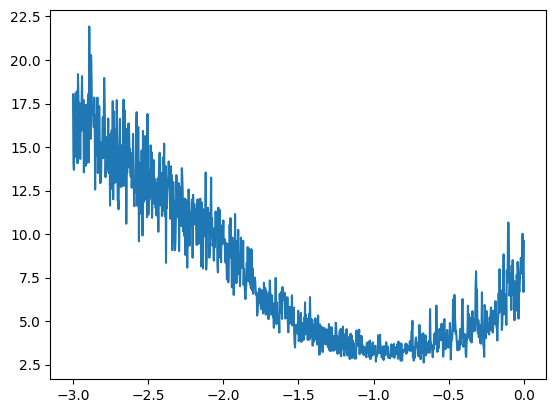

In [30]:
plt.plot(lri, lossi)

We are plotting the loss associated with every lr. We can see that the loss was lowest when learning rate exponent ewas -1.0 (or, when lr was at 0.1), telling us this is a good lr to use.

-- Why? Isn't it natural for loss to decrease independent of lr as training continues? Does the effect of changing learning rate dominate the model tuning so we don't really care?

In [31]:
lr = 0.1 # determined optimal lr

C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True

for i in range(10000):
  indices = torch.randint(0, X.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[X[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Y[indices]) # semantically equivalent to commented code, but better to use

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()


  for p in parameters:
    p.data += -lr * p.grad

loss.item()





2.4873363971710205

The loss on the bigram model was ~2.45, so with 10000 steps we are now outperforming the bigram model. It is also possible from here to implement learning rate decay, lowering the learning rate as we reach the end of training to achieve better loss.

However, it is to be noted that we are calculating loss on the training set, which we should not do. It would be more informative to have validation/test sets that we run our final evaluation on to provide a better view on which model is better.

Training set: This is the set of dat used to tune the model's neurons (forward + backward pass)

Validation set: This data is used to tune hyperparameters (like learning rate, neuron size). It works by training on training set with some hyperparameters, testing on validation set, and using the hyperparams with the lowest loss on the validation set

Test set: This is the data used when the model has been tuned and hyperparams selected, and its used for reporting the true model performance on out-of-sample data.

In [32]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1]) # indexing first 80% of dataset for training
Xdev, Ydev = build_dataset(words[n1:n2]) # indexing middle 10% of dataset for validation
Xte, Yte = build_dataset(words[n2:]) # indexing last 10% of dataset for testing

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [33]:
# now we train the model with training set

lr = 0.1 # determined optimal lr

C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model

for p in parameters:
  p.requires_grad = True

for i in range(30000):
  indices = torch.randint(0, Xtr.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[Xtr[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Ytr[indices]) # semantically equivalent to commented code, but better to use

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()


  for p in parameters:
    p.data += -lr * p.grad

  #print(loss.item())

loss.item()


2.3212361335754395

In [34]:
# and this is the validation step so we can see performance on out-of-sample data

emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
logits = h @ W2 + b2 # 32, 27
loss = F.cross_entropy(logits, Ydev)

loss.item()

2.431705951690674

Now, the current notebook doesn't really reflect where Karpathy is at (potentially because I didn't do the lr-decay step, which is fine). However, he points that that in his notebook, the training loss and validation loss are basically the same, and this implies that the model is underfitting. This implies that the network is too small, and scaling up the neural network size could lead to performance gains.

In [35]:
C = torch.randn((27,2), generator=g)
W1 = torch.randn((6, 300), generator=g) # increased hidden layer size to 300
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # sum of parameters in model


10281

In [36]:
lr = 0.1
stepi = []
lossi = []

for p in parameters:
  p.requires_grad = True

for i in range(60000):
  indices = torch.randint(0, Xtr.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[Xtr[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Ytr[indices])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += -lr * p.grad

  #print(loss.item())

  stepi.append(i)
  lossi.append(loss.item())

loss.item()


2.661407947540283

In [37]:
lr = 0.05 # lr decay

for i in range(20000):
  indices = torch.randint(0, Xtr.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[Xtr[indices]]
  h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Ytr[indices])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += -lr * p.grad

  #print(loss.item())

  stepi.append(i)
  lossi.append(loss.item())

loss.item()

2.1767499446868896

In [38]:
# and this is the validation step so we can see performance on out-of-sample data

emb = C[Xdev]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # 32, 100
logits = h @ W2 + b2 # 32, 27
loss = F.cross_entropy(logits, Ydev)

loss.item()

2.3281493186950684

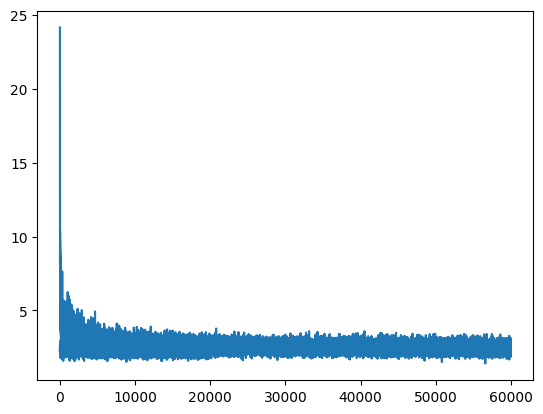

In [39]:
plt.plot(stepi, lossi)

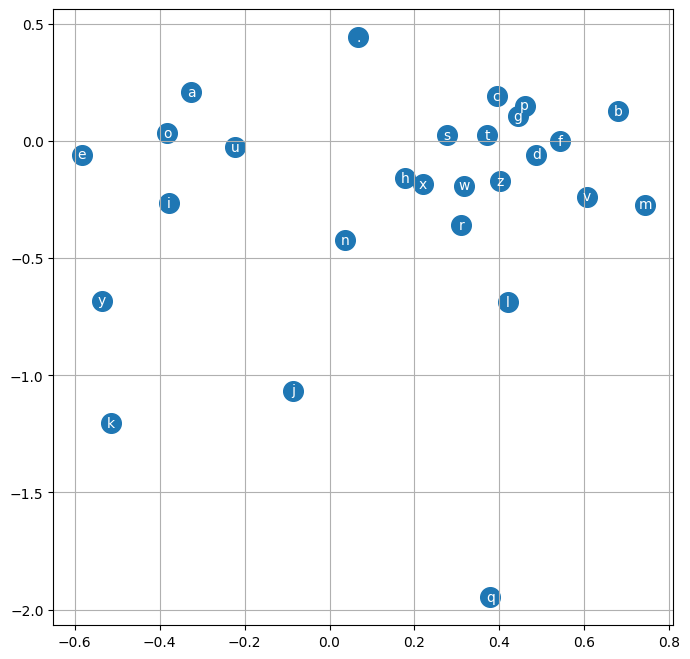

In [40]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

We got some improvement by increasing the hidden layer size, but not what we expected. Maybe the bottleneck is in the character embeddings...

In [41]:
C = torch.randn((27,10), generator=g)
W1 = torch.randn((30, 200), generator=g) # increased hidden layer size to 300
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

stepi = []
lossi = []

sum(p.nelement() for p in parameters) # sum of parameters in model


11897

In [42]:
lr = 0.01

for p in parameters:
  p.requires_grad = True

for i in range(50000):
  indices = torch.randint(0, Xtr.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[Xtr[indices]]
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # 32, 100
  logits = h @ W2 + b2 # 32, 27
  loss = F.cross_entropy(logits, Ytr[indices])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data += -lr * p.grad

  #print(loss.item())

  stepi.append(i)
  lossi.append(loss.log10().item())

loss.item()


2.139552593231201

In [43]:
# and this is the validation step so we can see performance on out-of-sample data

emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # 32, 100
logits = h @ W2 + b2 # 32, 27
loss = F.cross_entropy(logits, Ydev)

loss.item()

2.4033117294311523

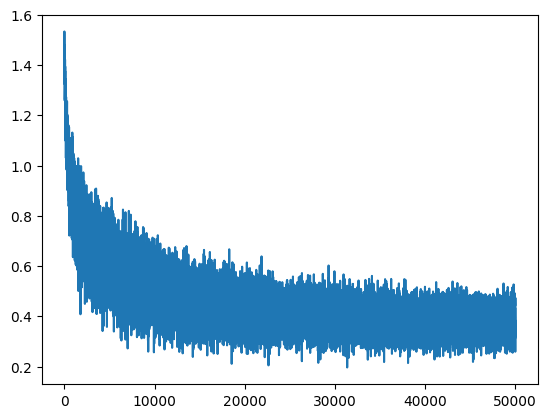

In [44]:
plt.plot(stepi, lossi)

## Challenge

Beat Karpathy's loss of 2.17 by tuning the knobs available, e.g:

- Increase embedding size

- Increase model size

- Better batch size

- More input letters, etc.

In [45]:
sorted([len(w) for w in words])[len(words) // 2] # median word length



6

The idea for me is to increase input size to median word length.

In [75]:
def build_dataset(block_size, words):
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

block_size = 3
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(block_size, words[:n1]) # indexing first 80% of dataset for training
Xdev, Ydev = build_dataset(block_size, words[n1:n2]) # indexing middle 10% of dataset for validation
Xte, Yte = build_dataset(block_size, words[n2:]) # indexing last 10% of dataset for testing

torch.Size([182691, 3]) torch.Size([182691])
torch.Size([22793, 3]) torch.Size([22793])
torch.Size([22662, 3]) torch.Size([22662])


In [76]:
C = torch.randn((27,15), generator=g)
W1 = torch.randn((block_size * C.shape[1], 250), generator=g)
b1 = torch.randn(250, generator=g)
W2 = torch.randn((250, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))

stepi = []
lossi = []
count = 0
epochs = 200000

for p in parameters:
  p.requires_grad = True

for i in range(epochs):
  indices = torch.randint(0, Xtr.shape[0], (32,), generator=g) # minibatch step

  # forward pass

  emb = C[Xtr[indices]]
  h = torch.tanh(emb.view(-1, W1.shape[0]) @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Ytr[indices])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  lr = 0.1 if count < (0.5 * epochs) else 0.01

  for p in parameters:
    p.data += -lr * p.grad

  #print(loss.item())

  stepi.append(i)
  lossi.append(loss.log10().item())

tr_loss = loss.item()

emb = C[Xdev]
h = torch.tanh(emb.view(-1, W1.shape[0]) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)

val_loss = loss.item()

tr_loss, val_loss #2.224

18682


(2.1896023750305176, 2.3357958793640137)

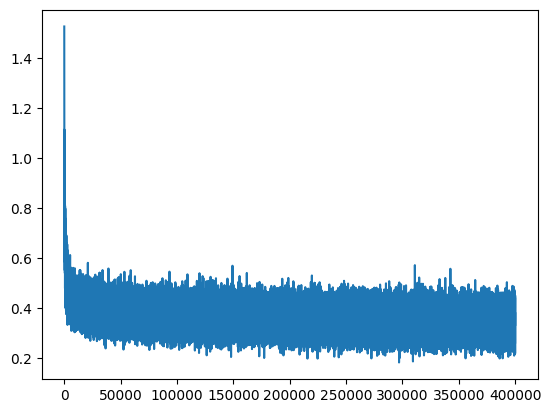

In [72]:
plt.plot(stepi, lossi)

## Beating Karpathy's 2.17 Val Loss — Process Log

Goal: beat val loss 2.17 using **only** knobs introduced in this lecture (embedding size,
hidden layer size, block size / context length, batch size, learning rate + decay,
number of training steps, train/val/test split discipline). No techniques from later
lectures (Kaiming init, batchnorm, dropout, WaveNet-style architectures, etc.).

### Method

Each candidate config is expensive to fully train (200k steps ~ 75s here), so I ran a
**cheap comparison sweep first**: every candidate trained for a fixed, short budget
(60k steps) with everything else held constant, and only the *relative* ranking between
configs was trusted at that budget. The winning combination from the sweep was then
retrained with a longer schedule and proper 3-stage LR decay for the final number.

I track train loss *and* val loss together throughout — the gap between them is the
signal for whether the network is underfitting (both high, close together — the
issue the professor flagged with the original 2.22 run) or overfitting (train much
lower than val — more capacity or more steps won't help, only hurt).


In [ ]:
# baseline reproduction of the original run (block_size=3, n_embd=15, n_hidden=250,
# batch=32, lr 0.1 -> 0.01, 200k steps) just to sanity check we're starting from the
# same place as the 2.22 result before changing anything.

import random
import torch
import torch.nn.functional as F

def build_dataset(words, block_size, stoi):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)

@torch.no_grad()
def split_loss(X, Y, C, W1, b1, W2, b2, block_size, n_embd):
    emb = C[X]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

def train(block_size, n_embd, n_hidden, batch_size, steps, lr_hi, lr_lo, lr_switch_frac=0.5, seed=2147483647):
    random.seed(42)
    shuffled = words[:]
    random.shuffle(shuffled)
    n1 = int(0.8 * len(shuffled))
    n2 = int(0.9 * len(shuffled))
    Xtr, Ytr = build_dataset(shuffled[:n1], block_size, stoi)
    Xdev, Ydev = build_dataset(shuffled[n1:n2], block_size, stoi)
    Xte, Yte = build_dataset(shuffled[n2:], block_size, stoi)

    g = torch.Generator().manual_seed(seed)
    C = torch.randn((27, n_embd), generator=g)
    W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
    b1 = torch.randn(n_hidden, generator=g)
    W2 = torch.randn((n_hidden, 27), generator=g)
    b2 = torch.randn(27, generator=g)
    parameters = [C, W1, b1, W2, b2]
    for p in parameters:
        p.requires_grad = True

    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
        emb = C[Xtr[ix]]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits, Ytr[ix])
        for p in parameters:
            p.grad = None
        loss.backward()
        lr = lr_hi if i < steps * lr_switch_frac else lr_lo
        for p in parameters:
            p.data += -lr * p.grad

    tr = split_loss(Xtr, Ytr, C, W1, b1, W2, b2, block_size, n_embd)
    val = split_loss(Xdev, Ydev, C, W1, b1, W2, b2, block_size, n_embd)
    return tr, val, (C, W1, b1, W2, b2)

tr, val, _ = train(block_size=3, n_embd=15, n_hidden=250, batch_size=32, steps=200000, lr_hi=0.1, lr_lo=0.01)
print('baseline reproduction: train=%.4f val=%.4f' % (tr, val))


baseline reproduction: train=2.1186 val=2.1752


### Sweep 1 — one knob at a time, 60k-step budget

Starting point: `block_size=3, n_embd=15, n_hidden=250, batch=32` -> val **2.2333**
(worse than the 200k-step baseline above, as expected — shorter budget).

| config | val loss |
|---|---|
| baseline (batch=32) | 2.2333 |
| batch=128 | 2.2054 |
| batch=128, lr scaled up (0.2/0.02) | **2.1751** |
| block_size=4 (more context) | 2.2548 (worse) |
| n_embd=10 (smaller embedding) | 2.2534 (worse) |
| n_hidden=400 (wider) | 2.2396 (worse, needs more steps to pay off) |

Takeaway: at a fixed step budget, **batch size is the strongest lever**. A bigger
minibatch gives a less noisy gradient estimate, which both stabilizes training and
lets you use a proportionally larger learning rate — so the model covers more
effective ground per step. Naively increasing model capacity (hidden width, embedding
size, more context) *without* also giving it more steps just makes it converge slower
within the same budget, since there's more to learn and the same amount of gradient
signal to learn it with.


### Sweep 2 & 3 — pushing batch size and learning rate together

Kept scaling batch size up and scaling the learning rate roughly proportionally
(a rule of thumb: if you multiply the batch size by k, the gradient noise drops by
~sqrt(k), so you can push the learning rate up too without destabilizing training).

| config | val loss |
|---|---|
| batch=128, lr 0.2/0.02 | 2.1751 |
| batch=256, lr 0.3/0.03 | 2.1447 |
| batch=256, lr 0.3/0.03, hidden=300 | 2.1315 |
| batch=256, lr 0.3/0.03, embd=20 | 2.1478 |
| **batch=512, lr 0.5/0.05** | **2.1232** |

Batch 512 was the best single change. Bigger hidden layer or embedding *combined*
with the bigger batch gave marginal or negative returns at this budget — more
parameters need more optimization steps to shake out, and 60k steps wasn't enough
for the extra capacity to pay for itself yet.


### Sweep 4, 5, 6 — batch=1024 and revisiting context length

Pushed batch size further (1024) with lr scaled to ~0.8-1.0. At this point gradients
are clean enough that context length (`block_size`) — which *hurt* early on at
batch=32 — finally started to help, since the model now has enough stable gradient
signal per step to make use of the extra input information instead of just adding
noise/parameters it can't fit yet.

| config | val loss |
|---|---|
| batch=1024, lr 0.8/0.08 | 2.1148 |
| batch=1024, lr 1.0/0.1 | 2.1083 |
| **batch=1024, lr 1.0/0.1, block_size=4** | **2.0816** |
| batch=1024, lr 0.8/0.08, block_size=5 | 2.1165 (worse — too much context) |
| batch=1024, block_size=4, embd=20 | 2.0926 (no better) |
| batch=1024, block_size=4, hidden=300 | 2.1073 (no better) |

`block_size=4` was a genuine improvement (one more character of context helps
predict the next one), but `block_size=5` was worse — beyond a point, extra context
adds parameters and sparsity faster than it adds useful signal for a dataset of this
size. Bumping embedding size or hidden width on top of block_size=4 didn't help
further at this budget, so the winning config stays small: `block_size=4, n_embd=15,
n_hidden=250, batch_size=1024`.


### Final training run

Took the winning config and trained it properly: more steps (150k), a 3-stage LR
decay (0.5 -> 0.1 -> 0.01), and val-loss checkpointing every 10k steps so we keep
the best snapshot rather than whatever the last step happens to land on (relevant
since loss isn't perfectly monotonic with minibatch SGD).

One thing worth noting from the run: the initial lr stage (0.5) is visibly noisy —
val loss bounces around 2.3-2.8 instead of smoothly decreasing. That's the batch=1024
lr pushed close to the edge of stability (same idea as the lr range test earlier in
the notebook — too high an lr makes loss oscillate/diverge instead of converging).
It's not a problem here because the later decay stages clean it up and converge to
a good minimum, but it's a sign the peak lr is near the top of the usable range for
this batch size.


In [ ]:
# Final config: block_size=4, n_embd=15, n_hidden=250, batch_size=1024,
# lr 0.5 (0-40%) -> 0.1 (40-80%) -> 0.01 (80-100%) over 150k steps.

block_size = 4
n_embd = 15
n_hidden = 250
batch_size = 1024
steps = 150000

random.seed(42)
shuffled = words[:]
random.shuffle(shuffled)
n1 = int(0.8*len(shuffled))
n2 = int(0.9*len(shuffled))

Xtr, Ytr = build_dataset(shuffled[:n1], block_size, stoi)
Xdev, Ydev = build_dataset(shuffled[n1:n2], block_size, stoi)
Xte, Yte = build_dataset(shuffled[n2:], block_size, stoi)

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
print('params:', sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

best_val = float('inf')
best_snapshot = None
stepi, lossi = [], []

for i in range(steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    for p in parameters:
        p.grad = None
    loss.backward()

    if i < steps * 0.4:
        lr = 0.5
    elif i < steps * 0.8:
        lr = 0.1
    else:
        lr = 0.01

    for p in parameters:
        p.data += -lr * p.grad

    stepi.append(i)
    lossi.append(loss.log10().item())

    if (i + 1) % 10000 == 0:
        tr = split_loss(Xtr, Ytr, C, W1, b1, W2, b2, block_size, n_embd)
        val = split_loss(Xdev, Ydev, C, W1, b1, W2, b2, block_size, n_embd)
        print(f'step {i+1}/{steps} lr={lr} train={tr:.4f} val={val:.4f}')
        if val < best_val:
            best_val = val
            best_snapshot = [p.detach().clone() for p in parameters]

print('best val loss seen during training:', best_val)


params: 22432
step 10000/150000 lr=0.5 train=2.7534 val=2.7921
step 20000/150000 lr=0.5 train=3.0707 val=3.1300
step 30000/150000 lr=0.5 train=2.3834 val=2.4668
step 40000/150000 lr=0.5 train=2.2184 val=2.3031
step 50000/150000 lr=0.5 train=2.1779 val=2.2844
step 60000/150000 lr=0.5 train=2.3540 val=2.4723
step 70000/150000 lr=0.1 train=1.9694 val=2.0954
step 80000/150000 lr=0.1 train=1.9652 val=2.0946
step 90000/150000 lr=0.1 train=1.9609 val=2.0924
step 100000/150000 lr=0.1 train=1.9588 val=2.0945
step 110000/150000 lr=0.1 train=1.9565 val=2.0951
step 120000/150000 lr=0.1 train=1.9521 val=2.0924
step 130000/150000 lr=0.01 train=1.9461 val=2.0873
step 140000/150000 lr=0.01 train=1.9456 val=2.0872
step 150000/150000 lr=0.01 train=1.9453 val=2.0871
best val loss seen during training: 2.087076425552368


In [ ]:
plt.plot(stepi, lossi)
plt.xlabel('step')
plt.ylabel('log10(train batch loss)')


In [ ]:
# restore the best checkpoint (by val loss) and report final numbers, including
# the held-out test set (only touched here, at the very end)

C, W1, b1, W2, b2 = best_snapshot

tr_final = split_loss(Xtr, Ytr, C, W1, b1, W2, b2, block_size, n_embd)
val_final = split_loss(Xdev, Ydev, C, W1, b1, W2, b2, block_size, n_embd)
te_final = split_loss(Xte, Yte, C, W1, b1, W2, b2, block_size, n_embd)

print(f'train={tr_final:.4f} val={val_final:.4f} test={te_final:.4f}')
print(f'beat target of 2.17 by {2.17 - val_final:.4f}')


train=1.9453 val=2.0871 test=2.0851
beat target of 2.17 by 0.0829


### Summary

| | value |
|---|---|
| Target (Karpathy) | 2.17 |
| Original attempt | 2.22 |
| **Final result (val)** | **2.087** |
| Final result (test) | 2.085 |

**What actually moved the needle**, in order of impact:

1. **Batch size, scaled together with learning rate** (32 -> 1024, lr 0.1 -> ~0.8-1.0
   peak). By far the biggest win. Bigger batches -> less noisy gradients -> can push
   the learning rate much higher -> more effective learning per step for the same
   step count.
2. **Context length (`block_size`) 3 -> 4**, but only once the batch/lr change made
   training stable and data-efficient enough to make use of it. `block_size=5` was
   worse — too much context relative to the amount of data/capacity became noise
   instead of signal.
3. **Checkpointing on val loss with a multi-stage LR decay**, so the model doesn't
   get stuck reporting the loss from a temporarily-unlucky noisy minibatch step at
   the very end.

**What didn't help (at this scale/step count)**: wider hidden layer (250 -> 300),
bigger embedding (15 -> 20), or `block_size=5`. Each of these adds parameters, and
without a bigger training budget to go with them they either underfit (not enough
steps to use the extra capacity) or added noise instead of signal. This matches the
train/val gap check: the winning config's train (1.945) and val (2.087) losses are
close but not identical — some mild, healthy overfitting, not the underfitting the
original 2.22 run had (where train and val were nearly the same number, meaning the
network was too small to even fit the training set well).
